In [5]:
import numpy as np
import matplotlib.pyplot as plt

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


#### the pure basis blade multiplication-resolution

In [6]:
from pga_engine.layer1 import ENUM_2_BLADE, BLADE_2_ENUM
from pga_engine.layer1 import resolve_bb_mult_bitmask

# test
bb1 = ENUM_2_BLADE[15]
bb2 = ENUM_2_BLADE[8]

sgn, out = resolve_bb_mult_bitmask(bb1, bb2)

print(f"input: bb1={bb1:0>4b} bb2={bb2:0>4b}")
print(f"result: {sgn=} and {out=:0>4b}")

input: bb1=1111 bb2=0110
result: sgn=-1 and out=1001


#### building the cayley table

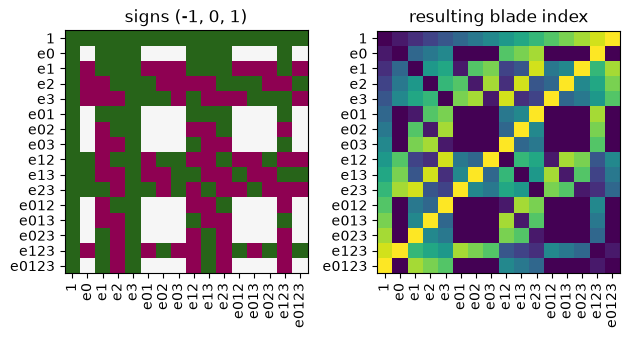

In [9]:
from pga_engine.layer1 import CAYLEY_SIGNS, CAYLEY_TABLE

fig, axs = plt.subplots(1, 2)
names = ["1"] + ["e" + "".join(str(k) for k in range(4) if b >> k & 1) for b in ENUM_2_BLADE[1:]]
axs[0].imshow(CAYLEY_SIGNS, cmap="PiYG", vmin=-1, vmax=1) 
axs[0].set_title("signs (-1, 0, 1)")
axs[0].set_xticks(range(16), names, rotation=90); axs[0].set_yticks(range(16), names)
axs[1].imshow(CAYLEY_TABLE)
axs[1].set_title("resulting blade index")
axs[1].set_xticks(range(16), names, rotation=90); axs[1].set_yticks(range(16), names)
fig.tight_layout()
plt.show()

In [11]:
from pga_engine.layer1 import gp
       

rng = np.random.default_rng(0)
A, B, C = rng.normal(size=(3, 16))
one = np.zeros(16); one[0] = 1

# identity holds
assert np.allclose(gp(one, A), A)
assert np.allclose(gp(A, one), A)

# associative
side1 = gp(gp(A, B), C)
side2 = gp(A, gp(B, C))
assert np.allclose(side1, side2)

# distributive
side1 = gp(A, B + C)
side2 = gp(A, B) + gp(A, C)
assert np.allclose(side1, side2)

# linear
side1 = gp(2 * A, B)
side2 = 2 * gp(A, B)
assert np.allclose(side1, side2)

# NOT commutative
side1 = gp(A, B)
side2 = gp(B, A)
assert not np.allclose(side1, side2)  